# Titanic: classify survival with a Random Forest

Original reference: [GeeksforGeeks: Random Forest](https://www.geeksforgeeks.org/machine-learning/random-forest-algorithm-in-machine-learning/).

Use passenger characteristics to predict survival and examine the errors made on a held-out test set.

### Topics
- Prepare categorical and missing values
- Choose features and split the data
- Train a Random Forest classifier
- Read a classification report and confusion matrix

**Question for the lesson:** Which survival outcomes does the model predict well, and where does it make mistakes?

> **Estimated time: 60 min**

## 1 · Import the tools

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

## 2 · Load and inspect passenger records

Read `titanic.csv` from the notebook folder. The target is `Survived`: `0` means did not survive and `1` means survived. Inspect the available columns before selecting inputs.

In [3]:
titanic_data = pd.read_csv('titanic.csv')
titanic_data

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


## 3 · Prepare the model inputs

Drop rows without a known survival label, encode `Sex` as `female = 0` and `male = 1`, and replace missing ages with the median.

In this introductory code, the age median is computed before the split, so it uses information from future test rows. For a stricter evaluation, split first, learn the median on training rows, and reuse it for test rows.

In [4]:
titanic_data = titanic_data.dropna(subset=['Survived'])
titanic_data['Sex'] = titanic_data['Sex'].map({'female': 0, 'male': 1})
titanic_data['Age'] = titanic_data['Age'].fillna(titanic_data['Age'].median())

## 4 · Select features and split the data

Use passenger class (`Pclass`), encoded sex, age, siblings/spouses aboard (`SibSp`), parents/children aboard (`Parch`), and fare. Reserve 20% of rows for testing; `random_state=42` fixes the split.

In [5]:
X = titanic_data[['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare']]
y = titanic_data['Survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## 5 · Train a Random Forest classifier

Fit 100 trees on the training data. Trees learn varied rules from bootstrap samples and random feature subsets; the classifier averages their class probabilities to choose a class.

In [6]:
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_classifier.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

## 6 · Predict one passenger

Keep the first test passenger as a one-row DataFrame so column names and feature order are preserved. The printed passenger details show the inputs used to predict survival.

In [7]:
sample = X_test.iloc[[0]]
prediction = rf_classifier.predict(sample)

sample_dict = sample.iloc[0].to_dict()
print(f"Sample Passenger: {sample_dict}")
print(f"Predicted Survival: {'Survived' if prediction[0] == 1 else 'Did Not Survive'}")

Sample Passenger: {'Pclass': 3.0, 'Sex': 1.0, 'Age': 28.0, 'SibSp': 1.0, 'Parch': 1.0, 'Fare': 15.2458}
Predicted Survival: Did Not Survive


In [8]:
jack = pd.DataFrame([{
	'Pclass': 3,
	'Sex': 1,
	'Age': 20,
	'SibSp': 0,
	'Parch': 0,
	'Fare': 10
}])
prediction = rf_classifier.predict(jack)
print(prediction)

[0]


In [9]:
rose = pd.DataFrame([{
	'Pclass': 1,
	'Sex': 0,
	'Age': 17,
	'SibSp': 0,
	'Parch': 1,
	'Fare': 50
}])
prediction = rf_classifier.predict(rose)
print(prediction)

[1]


## 7 · Evaluate the classifier

Accuracy is the fraction of correct test predictions. The classification report adds precision, recall, F1-score, and support for each class. Precision asks how often a predicted class is correct; recall asks how many actual members of that class were found. F1 balances precision and recall, while support counts actual examples.

In [10]:
y_pred = rf_classifier.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
classification_rep = classification_report(y_test, y_pred)

print("Accuracy:", accuracy)
print("Classification Report:")
print(classification_rep)

Accuracy: 0.7988826815642458
Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.85      0.83       105
           1       0.77      0.73      0.75        74

    accuracy                           0.80       179
   macro avg       0.79      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179



## 8 · Read the confusion matrix

Rows represent actual classes and columns represent predicted classes. Here, `Class 0` means did not survive and `Class 1` means survived. Correct predictions lie on the diagonal; the other cells show the two types of error.

### Pause & interpret

Which class has higher recall? Use the report and matrix together to explain which passengers the model most often misclassifies.

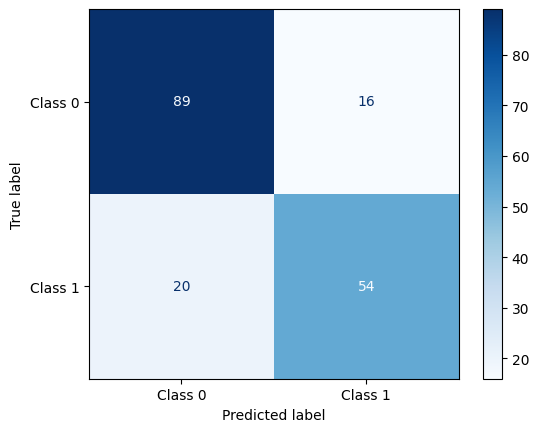

In [11]:
cm = confusion_matrix(y_test, y_pred)

# 2. Plot the matrix visually
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Class 0', 'Class 1'])
disp.plot(cmap=plt.cm.Blues)
plt.show()

## Key takeaways

- Classification predicts discrete labels such as survived or did not survive.
- Encode categories and handle missing inputs before fitting a model.
- Fit learned preprocessing steps using training rows only.
- A confusion matrix and per-class metrics explain more than accuracy alone.

------------

assignment -- Aryan Hashemi

--------------

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, export_text

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

df = pd.read_csv('titanic.csv')

display(df.head())
print("Dataset shape:", df.shape)
display(df.isnull().sum())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Dataset shape: (891, 12)


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [13]:
df['Sex'] = df['Sex'].map({'female': 0, 'male': 1})

df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
df['IsAlone'] = (df['FamilySize'] == 1).astype(int)

df['HasCabin'] = df['Cabin'].notna().astype(int)
df['AgeMissing'] = df['Age'].isna().astype(int)

df['Title'] = df['Name'].str.extract(
    r',\s*([^.]*)\.',
    expand=False
).str.strip()

df['Title'] = df['Title'].replace({
    'Mlle': 'Miss',
    'Ms': 'Miss',
    'Mme': 'Mrs'
})

df['Title'] = df['Title'].map({
    'Mr': 0,
    'Miss': 1,
    'Mrs': 2,
    'Master': 3
}).fillna(4).astype(int)

df['Embarked'] = df['Embarked'].map({
    'S': 0,
    'C': 1,
    'Q': 2
}).fillna(3).astype(int)

df['Deck'] = df['Cabin'].str[0].map({
    'A': 1,
    'B': 2,
    'C': 3,
    'D': 4,
    'E': 5,
    'F': 6,
    'G': 7,
    'T': 8
}).fillna(0).astype(int)

In [14]:
base_features = [
    'Pclass', 'Sex', 'Age',
    'SibSp', 'Parch', 'Fare'
]

extra_features = base_features + [
    'FamilySize', 'IsAlone',
    'HasCabin', 'AgeMissing',
    'Title', 'Embarked', 'Deck'
]

X = df[extra_features].copy()
y = df['Survived'].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Internal test rows:", len(X_test))

Training rows: 712
Internal test rows: 179


In [15]:
# Features, Trees, Max depth, Min samples leaf, Max features

settings = [
    ('Base', 100, None, 1, 'sqrt'),
    ('Extra', 400, None, 1, 'sqrt'),
    ('Extra', 400, 6, 2, 'sqrt'),
    ('Extra', 400, 8, 2, 'sqrt'),
    ('Extra', 400, 10, 2, 'sqrt'),
    ('Extra', 400, None, 3, 'sqrt'),
    ('Extra', 400, 6, 2, 0.8),
    ('Extra', 400, 8, 2, 0.8),
    ('Extra', 400, None, 3, 0.8)
]

settings_table = pd.DataFrame(
    settings,
    columns=[
        'Features', 'Trees', 'Max depth',
        'Min samples leaf', 'Max features'
    ]
)

display(settings_table)

,Features,Trees,Max depth,Min samples leaf,Max features
0,Base,100,NaN,1,sqrt
1,Extra,400,NaN,1,sqrt
2,Extra,400,6.0,2,sqrt
3,Extra,400,8.0,2,sqrt
4,Extra,400,10.0,2,sqrt
5,Extra,400,NaN,3,sqrt
6,Extra,400,6.0,2,0.8
7,Extra,400,8.0,2,0.8
8,Extra,400,NaN,3,0.8


In [16]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for i, setting in enumerate(settings):

    group, n, depth, leaf, max_features = setting

    if group == 'Base':
        features = base_features
    else:
        features = extra_features

    scores = []

    for train_index, valid_index in cv.split(X_train, y_train):

        fold_train = X_train.iloc[train_index][features].copy()
        fold_valid = X_train.iloc[valid_index][features].copy()

        fold_y_train = y_train.iloc[train_index]
        fold_y_valid = y_train.iloc[valid_index]

        fold_medians = fold_train.median()

        fold_train = fold_train.fillna(fold_medians)
        fold_valid = fold_valid.fillna(fold_medians)

        model = RandomForestClassifier(
            n_estimators=n,
            max_depth=depth,
            min_samples_leaf=leaf,
            max_features=max_features,
            random_state=42,
            n_jobs=-1
        )

        model.fit(fold_train, fold_y_train)
        predictions = model.predict(fold_valid)

        scores.append(
            accuracy_score(fold_y_valid, predictions)
        )

    results.append({
        'Model': i,
        'Features': group,
        'CV accuracy': np.mean(scores),
        'CV std': np.std(scores)
    })

    print("Model", i, "- CV accuracy:", round(np.mean(scores), 4))

cv_results = pd.DataFrame(results)

cv_results = cv_results.sort_values(
    'CV accuracy',
    ascending=False
).reset_index(drop=True)

display(cv_results.round(4))

Model 0 - CV accuracy: 0.823
Model 1 - CV accuracy: 0.8076
Model 2 - CV accuracy: 0.8188
Model 3 - CV accuracy: 0.8189
Model 4 - CV accuracy: 0.8203
Model 5 - CV accuracy: 0.8245
Model 6 - CV accuracy: 0.8301
Model 7 - CV accuracy: 0.8301
Model 8 - CV accuracy: 0.8343


,Model,Features,CV accuracy,CV std
0,8,Extra,0.8343,0.0148
1,6,Extra,0.8301,0.0202
2,7,Extra,0.8301,0.0212
3,5,Extra,0.8245,0.0210
4,0,Base,0.8230,0.0206
5,4,Extra,0.8203,0.0227
6,3,Extra,0.8189,0.0191
7,2,Extra,0.8188,0.0213
8,1,Extra,0.8076,0.0187


In [17]:
best_index = int(cv_results.loc[0, 'Model'])

group, n, depth, leaf, max_features = settings[best_index]

if group == 'Base':
    features = base_features
else:
    features = extra_features

X_train_ready = X_train[features].copy()
X_test_ready = X_test[features].copy()

age_median = X_train_ready['Age'].median()
fare_median = X_train_ready['Fare'].median()

X_train_ready['Age'] = X_train_ready['Age'].fillna(age_median)
X_test_ready['Age'] = X_test_ready['Age'].fillna(age_median)

X_train_ready['Fare'] = X_train_ready['Fare'].fillna(fare_median)
X_test_ready['Fare'] = X_test_ready['Fare'].fillna(fare_median)

print("Best model:", best_index)
print("Training age median:", age_median)

print("Missing values in train:", X_train_ready.isnull().sum().sum())
print("Missing values in test:", X_test_ready.isnull().sum().sum())

Best model: 8
Training age median: 28.5
Missing values in train: 0
Missing values in test: 0


اول داده‌ها رو به آموزش و تست تقسیم کردم و بعد میانه سن رو فقط از بخش آموزش به دست آوردم. از همون مقدار برای پرکردن سن‌های خالی در هر دو بخش استفاده کردم تا اطلاعات تست وارد پیش‌پردازش آموزش نشه. موقع اعتبارسنجی پنج‌بخشی هم این کار جداگانه داخل هر مرحله انجام شد.

In [18]:
rf_classifier = RandomForestClassifier(
    n_estimators=n,
    max_depth=depth,
    min_samples_leaf=leaf,
    max_features=max_features,
    random_state=42,
    n_jobs=-1
)

rf_classifier.fit(X_train_ready, y_train)

train_predictions = rf_classifier.predict(X_train_ready)
y_pred = rf_classifier.predict(X_test_ready)

print("Selected parameters:")
print("n_estimators:", n)
print("max_depth:", depth)
print("min_samples_leaf:", leaf)
print("max_features:", max_features)

print(
    "\nTraining accuracy:",
    round(accuracy_score(y_train, train_predictions), 4)
)

print(
    "Internal test accuracy:",
    round(accuracy_score(y_test, y_pred), 4)
)

print("\nClassification report:")

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=['Did not survive', 'Survived'],
    digits=4,
    zero_division=0
))

Selected parameters:
n_estimators: 400
max_depth: None
min_samples_leaf: 3
max_features: 0.8

Training accuracy: 0.9101
Internal test accuracy: 0.8045

Classification report:
                 precision    recall  f1-score   support

Did not survive     0.8049    0.9000    0.8498       110
       Survived     0.8036    0.6522    0.7200        69

       accuracy                         0.8045       179
      macro avg     0.8042    0.7761    0.7849       179
   weighted avg     0.8044    0.8045    0.7998       179



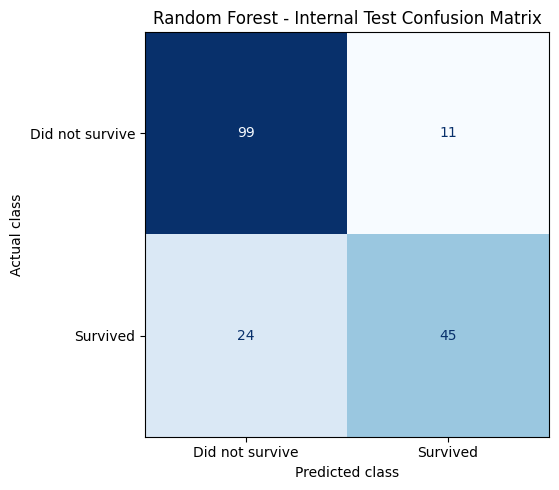

In [19]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Did not survive', 'Survived']
)

fig, ax = plt.subplots(figsize=(6, 5))

disp.plot(
    ax=ax,
    cmap='Blues',
    values_format='d',
    colorbar=False
)

plt.title('Random Forest - Internal Test Confusion Matrix')
plt.xlabel('Predicted class')
plt.ylabel('Actual class')
plt.tight_layout()
plt.show()

مثبت کاذب یعنی مدل گفته مسافر زنده مونده، ولی در واقع جان باخته؛ مدل من ۱۱ مورد از این خطا داشته. منفی کاذب یعنی مسافر واقعاً زنده مونده، ولی مدل پیش‌بینی کرده جان باخته؛ این خطا برای ۲۴ نفر اتفاق افتاده. Recall کلاس جان‌باخته‌ها ۹۰٪ و کلاس بازمانده‌ها حدود ۶۵٫۲۲٪ بوده، پس مدل سهم بیشتری از جان‌باخته‌های واقعی رو درست تشخیص داده.

In [20]:
tn, fp, fn, tp = cm.ravel()

recall_not_survived = tn / (tn + fp)
recall_survived = tp / (tp + fn)

print("False positives:", fp)
print("False negatives:", fn)

print("Did not survive recall:", round(recall_not_survived, 4))
print("Survived recall:", round(recall_survived, 4))

if recall_not_survived > recall_survived:
    print("Higher recall: Did not survive")
elif recall_survived > recall_not_survived:
    print("Higher recall: Survived")
else:
    print("Both classes have equal recall")

False positives: 11
False negatives: 24
Did not survive recall: 0.9
Survived recall: 0.6522
Higher recall: Did not survive


,Feature,Importance
10,Title,0.247891
1,Sex,0.186090
5,Fare,0.166077
2,Age,0.138960
0,Pclass,0.085231
6,FamilySize,0.051241
12,Deck,0.047487
11,Embarked,0.026100
8,HasCabin,0.017056
3,SibSp,0.016401


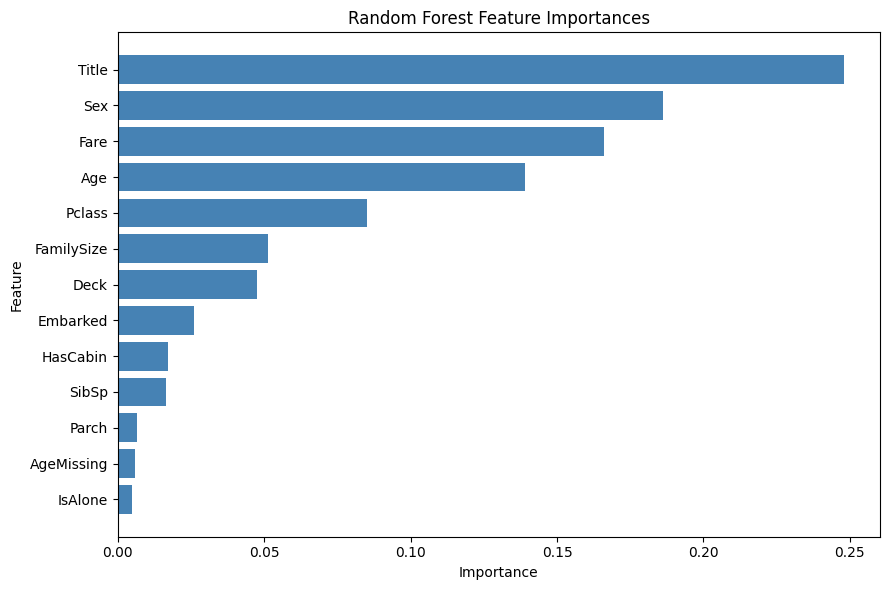

In [21]:
importances = pd.DataFrame({
    'Feature': features,
    'Importance': rf_classifier.feature_importances_
})

importances = importances.sort_values(
    'Importance',
    ascending=False
)

display(importances)

plt.figure(figsize=(9, 6))

plt.barh(
    importances['Feature'],
    importances['Importance'],
    color='steelblue'
)

plt.gca().invert_yaxis()

plt.title('Random Forest Feature Importances')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

عنوان داخل نام، جنسیت، مبلغ بلیت و سن بیشترین اهمیت رو در مدل داشتن. عنوان‌هایی مثل Mr، Mrs و Master بخشی از اطلاعات جنسیت و وضعیت سنی مسافر رو هم منتقل می‌کنن، برای همین می‌تونن به مدل کمک کنن. این اهمیت‌ها مربوط به نحوه تصمیم‌گیری همین مدل هستن و رابطه علت‌ومعلولی رو ثابت نمی‌کنن.

In [22]:
depth_results = []
decision_trees = {}

for depth_value in [1, 2, 4, 8]:

    dtree = DecisionTreeClassifier(
        max_depth=depth_value,
        random_state=42
    )

    dtree.fit(X_train_ready, y_train)

    train_pred = dtree.predict(X_train_ready)

    depth_results.append({
        'Maximum depth': depth_value,
        'Actual depth': dtree.get_depth(),
        'Number of leaves': dtree.get_n_leaves(),
        'Training accuracy': accuracy_score(y_train, train_pred)
    })

    decision_trees[depth_value] = dtree

depth_comparison = pd.DataFrame(depth_results)

display(depth_comparison.round(4))

,Maximum depth,Actual depth,Number of leaves,Training accuracy
0,1,1,2,0.7851
1,2,2,4,0.7949
2,4,4,15,0.8553
3,8,8,55,0.9157


In [23]:
for depth_value in [1, 2]:

    print("\nMaximum depth:", depth_value)

    print(export_text(
        decision_trees[depth_value],
        feature_names=features,
        decimals=2
    ))


Maximum depth: 1
|--- Title <= 0.50
|   |--- class: 0
|--- Title >  0.50
|   |--- class: 1


Maximum depth: 2
|--- Title <= 0.50
|   |--- Deck <= 2.50
|   |   |--- class: 0
|   |--- Deck >  2.50
|   |   |--- class: 0
|--- Title >  0.50
|   |--- Pclass <= 2.50
|   |   |--- class: 1
|   |--- Pclass >  2.50
|   |   |--- class: 0



با بیشترشدن عمق، درخت تونسته قواعد جزئی‌تری بسازه و تعداد برگ‌ها از ۲ به ۵۵ رسیده. دقت آموزش هم از حدود ۷۸٫۵۱٪ در عمق ۱ به ۹۱٫۵۷٪ در عمق ۸ افزایش پیدا کرده. البته این افزایش مربوط به داده‌های آموزشه و به‌تنهایی ثابت نمی‌کنه درخت عمیق‌تر روی داده‌های جدید بهتر عمل می‌کنه.

------------

Version kaggle dataset - با دیتاهای کگل و برای سابمیت

----------------

In [24]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier

train_data = pd.read_csv('train.csv')
test_data = pd.read_csv('test.csv')
sample_submission = pd.read_csv('gender_submission.csv')

print("Train shape:", train_data.shape)
print("Test shape:", test_data.shape)
print("Sample submission shape:", sample_submission.shape)

train_final = train_data.copy()
test_final = test_data.copy()

Train shape: (891, 12)
Test shape: (418, 11)
Sample submission shape: (418, 2)


In [25]:
for data in [train_final, test_final]:

    data['Sex'] = data['Sex'].map({
        'female': 0,
        'male': 1
    })

    data['FamilySize'] = data['SibSp'] + data['Parch'] + 1
    data['IsAlone'] = (data['FamilySize'] == 1).astype(int)

    data['HasCabin'] = data['Cabin'].notna().astype(int)
    data['AgeMissing'] = data['Age'].isna().astype(int)

    data['Title'] = data['Name'].str.extract(
        r',\s*([^.]*)\.',
        expand=False
    ).str.strip()

    data['Title'] = data['Title'].replace({
        'Mlle': 'Miss',
        'Ms': 'Miss',
        'Mme': 'Mrs'
    })

    data['Title'] = data['Title'].map({
        'Mr': 0,
        'Miss': 1,
        'Mrs': 2,
        'Master': 3
    }).fillna(4).astype(int)

    data['Embarked'] = data['Embarked'].map({
        'S': 0,
        'C': 1,
        'Q': 2
    }).fillna(3).astype(int)

    data['Deck'] = data['Cabin'].str[0].map({
        'A': 1,
        'B': 2,
        'C': 3,
        'D': 4,
        'E': 5,
        'F': 6,
        'G': 7,
        'T': 8
    }).fillna(0).astype(int)

In [26]:
final_age_median = train_final['Age'].median()
final_fare_median = train_final['Fare'].median()

for data in [train_final, test_final]:

    data['Age'] = data['Age'].fillna(final_age_median)
    data['Fare'] = data['Fare'].fillna(final_fare_median)

print("Training age median:", final_age_median)
print("Training fare median:", final_fare_median)

Training age median: 28.0
Training fare median: 14.4542


In [27]:
final_features = [
    'Pclass', 'Sex', 'Age',
    'SibSp', 'Parch', 'Fare',
    'FamilySize', 'IsAlone',
    'HasCabin', 'AgeMissing',
    'Title', 'Embarked', 'Deck'
]

X_full = train_final[final_features]
y_full = train_final['Survived'].astype(int)

X_kaggle = test_final[final_features]

assert not X_full.isnull().any().any()
assert not X_kaggle.isnull().any().any()

assert X_full.columns.equals(X_kaggle.columns)

assert set(train_data['PassengerId']).isdisjoint(
    test_data['PassengerId']
)

print("Training rows:", len(X_full))
print("Kaggle test rows:", len(X_kaggle))
print("Features:", len(final_features))

Training rows: 891
Kaggle test rows: 418
Features: 13


In [28]:
final_model = RandomForestClassifier(
    n_estimators=400,
    max_depth=None,
    min_samples_leaf=3,
    max_features=0.8,
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_full, y_full)

kaggle_predictions = final_model.predict(X_kaggle).astype(int)

print("Predictions:", len(kaggle_predictions))

Predictions: 418


In [29]:
submission = pd.DataFrame({
    'PassengerId': test_data['PassengerId'].astype(int),
    'Survived': kaggle_predictions
})

assert submission.shape == (418, 2)

assert list(submission.columns) == [
    'PassengerId', 'Survived'
]

assert not submission.isnull().any().any()
assert submission['PassengerId'].is_unique
assert submission['Survived'].isin([0, 1]).all()

assert submission['PassengerId'].equals(
    test_data['PassengerId']
)

assert set(submission['PassengerId']) == set(
    sample_submission['PassengerId']
)

display(submission.head(10))
display(submission['Survived'].value_counts())

print("All submission checks passed.")

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1
5,897,0
6,898,0
7,899,0
8,900,1
9,901,0


Survived
0    265
1    153
Name: count, dtype: int64

All submission checks passed.


In [30]:
submission.to_csv(
    'submission_titanic_rf.csv',
    index=False
)

saved_submission = pd.read_csv('submission_titanic_rf.csv')

assert saved_submission.equals(submission)

print("File saved successfully: submission_titanic_rf.csv")
print("Shape:", saved_submission.shape)
print("Columns:", saved_submission.columns.tolist())

File saved successfully: submission_titanic_rf.csv
Shape: (418, 2)
Columns: ['PassengerId', 'Survived']


بعد از انتخاب تنظیمات مدل با اعتبارسنجی، مدل نهایی رو روی تمام ۸۹۱ ردیف آموزش دادم. ویژگی‌های تست رو با همون روش ساختم و مقدارهای خالی رو فقط با میانه‌های داده آموزش پر کردم. در نهایت، پیش‌بینی ۴۱۸ مسافر رو با ستون‌های PassengerId و Survived و بدون ایندکس ذخیره کردم.